<a href="https://colab.research.google.com/github/cv2507/MASY1500_GROUP8_SNOWFLAKE_M2/blob/main/M3_Visualizations_Group8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CFPB Consumer Complaints - Milestone 3 Visualizations
**MASY1-GC1500 Group 8**

**Problem statement:** Which financial institutions, products and regions generated the most consumer complaints between August 2023 and August 2026, and how quickly and effectively did companies respond to them?



In [1]:
%pip install -q "snowflake-connector-python[pandas]" snowflake-sqlalchemy "sqlalchemy<2.1" seaborn

## 1. Connect to Snowflake
Must type in password to acess data (krb9975 snowflake password)

In [2]:
import os
import getpass
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from snowflake.sqlalchemy import URL
from sqlalchemy import create_engine

if "SNOWFLAKE_PASSWORD" not in os.environ:
    os.environ["SNOWFLAKE_PASSWORD"] = getpass.getpass("Snowflake password: ")

engine = create_engine(URL(
    account=os.environ.get("SNOWFLAKE_ACCOUNT", "gsvfbpn-hl39049"),
    user=os.environ.get("SNOWFLAKE_USER", "KRB9975"),
    password=os.environ["SNOWFLAKE_PASSWORD"],
    database="CFPB_CAPSTONE_DB",
    schema="CFPB_SCHEMA",
    warehouse=os.environ.get("SNOWFLAKE_WAREHOUSE", "COMPUTE_WH"),
    role=os.environ.get("SNOWFLAKE_ROLE", "PUBLIC"),
))

# Quick check that the deployed tables are reachable
pd.read_sql("select count(*) as complaint_rows from consumer_complaints", engine)

Snowflake password: ··········


,complaint_rows
0,10000


In [3]:
# One look for every chart
sns.set_theme(style="whitegrid", context="notebook")
BAR = "#2a78d6"      # single-series color
INK = "#52514e"      # secondary text
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK})


def label_bars(ax, fmt="{:,.0f}"):
    """Write each bar's value at its end, in text ink (not the bar color)."""
    for bar in ax.patches:
        ax.annotate(fmt.format(bar.get_width()),
                    (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK)

## 2. Which 10 companies receive the most consumer complaints?
*Why it matters:* a compliance analyst needs to know which institutions carry the most complaint volume before comparing how well they handle it.


In [4]:
q1 = """
select fc.company_name, count(*) as complaint_count
from consumer_complaints cc
join financial_companies fc on fc.company_id = cc.company_id
group by fc.company_name
order by complaint_count desc
fetch first 10 rows only
"""
top_companies = pd.read_sql(q1, engine)
top_companies["complaint_count"] = top_companies["complaint_count"].astype(int)
top_companies

,company_name,complaint_count
0,Experian Information Solutions Inc.,5892
1,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",2556
2,"EQUIFAX, INC.",553
3,SYNCHRONY FINANCIAL,83
4,"BANK OF AMERICA, NATIONAL ASSOCIATION",66
5,Conduent Incorporated,56
6,"Kriya Capital, LLC",42
7,"National Credit Adjusters, LLC",40
8,CAPITAL ONE FINANCIAL CORPORATION,31
9,WELLS FARGO & COMPANY,29


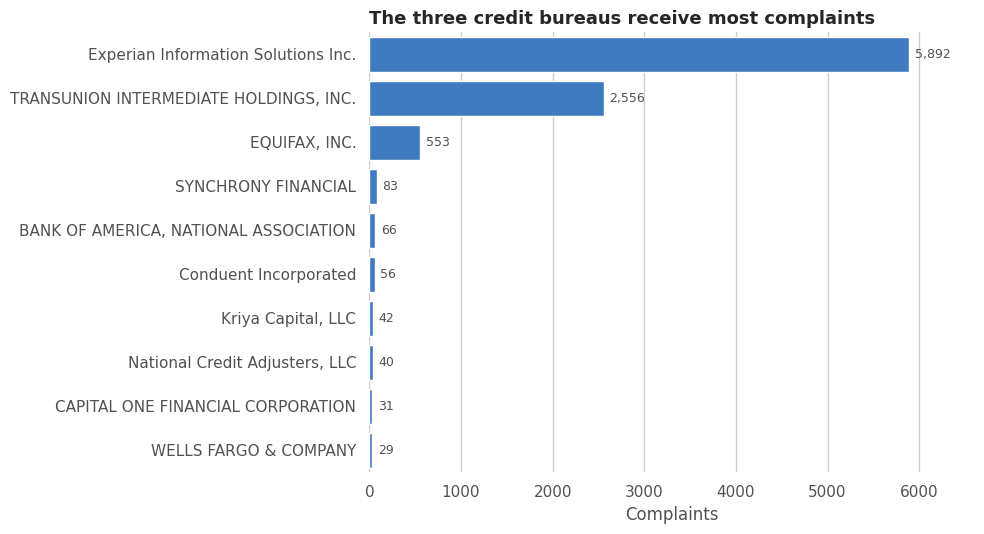

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=top_companies, y="company_name", x="complaint_count", color=BAR, ax=ax)
label_bars(ax)
ax.set_title("The three credit bureaus receive most complaints", loc="left")
ax.set(xlabel="Complaints", ylabel="")
ax.margins(x=0.12)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** Experian, TransUnion and Equifax account for 9,001 of the 10,000 complaints (90%). The largest non-bureau, Synchrony Financial, has 83.

## 3. Which 10 states generate the most complaints?
*Why it matters:* regional concentration shows where consumer pain points cluster and where outreach or supervision would reach the most people.

In [6]:
q4 = """
select gl.state_code, count(*) as complaint_count,
       round(ratio_to_report(count(*)) over () * 100, 2) as pct_of_complaints
from consumer_complaints cc
join geographic_locations gl on gl.location_id = cc.location_id
where gl.state_code != 'UNKNOWN'
group by gl.state_code
order by complaint_count desc
fetch first 10 rows only
"""
top_states = pd.read_sql(q4, engine)
top_states["complaint_count"] = top_states["complaint_count"].astype(int)
top_states["pct_of_complaints"] = top_states["pct_of_complaints"].astype(float)
top_states

,state_code,complaint_count,pct_of_complaints
0,TX,1601,16.04
1,FL,1500,15.03
2,CA,896,8.98
3,GA,734,7.35
4,NY,521,5.22
5,NC,356,3.57
6,IL,342,3.43
7,PA,326,3.27
8,AL,312,3.13
9,NJ,266,2.67


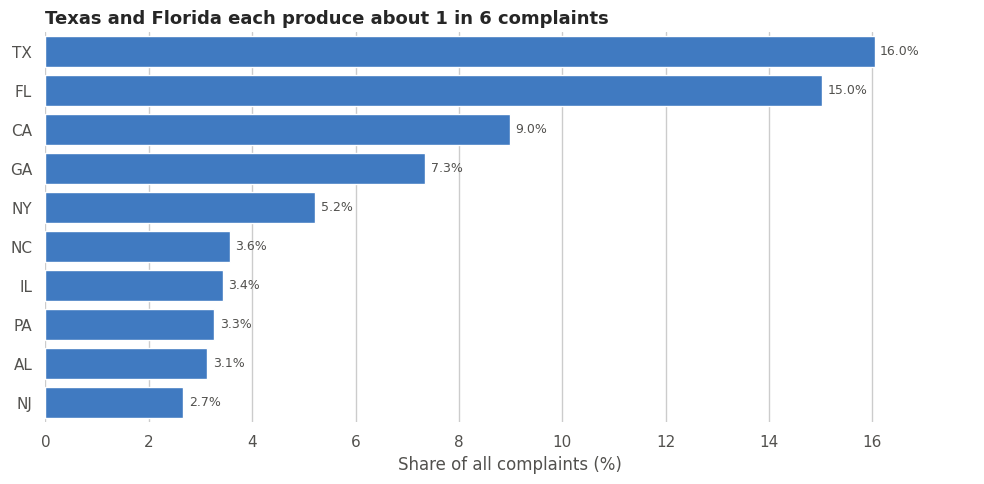

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_states, y="state_code", x="pct_of_complaints", color=BAR, ax=ax)
label_bars(ax, fmt="{:.1f}%")
ax.set_title("Texas and Florida each produce about 1 in 6 complaints", loc="left")
ax.set(xlabel="Share of all complaints (%)", ylabel="")
ax.margins(x=0.12)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** TX and FL lead by a wide margin. Together they produce more complaints than the next four states combined.

## 4. How has daily complaint volume changed over the most recent period?
*Why it matters:* tracking volume over time shows whether complaints are rising or falling and flags spikes worth investigating.



In [8]:
q_daily = """
select cc.date_received, count(*) as complaint_count
from consumer_complaints cc
where cc.date_received >= date '2026-07-01'
group by cc.date_received
order by cc.date_received
"""
daily = pd.read_sql(q_daily, engine)
daily["date_received"] = pd.to_datetime(daily["date_received"])
daily["complaint_count"] = daily["complaint_count"].astype(int)
daily.tail()

,date_received,complaint_count
50,2026-08-20,41
51,2026-08-21,10
52,2026-08-22,3
53,2026-08-23,5
54,2026-08-24,4


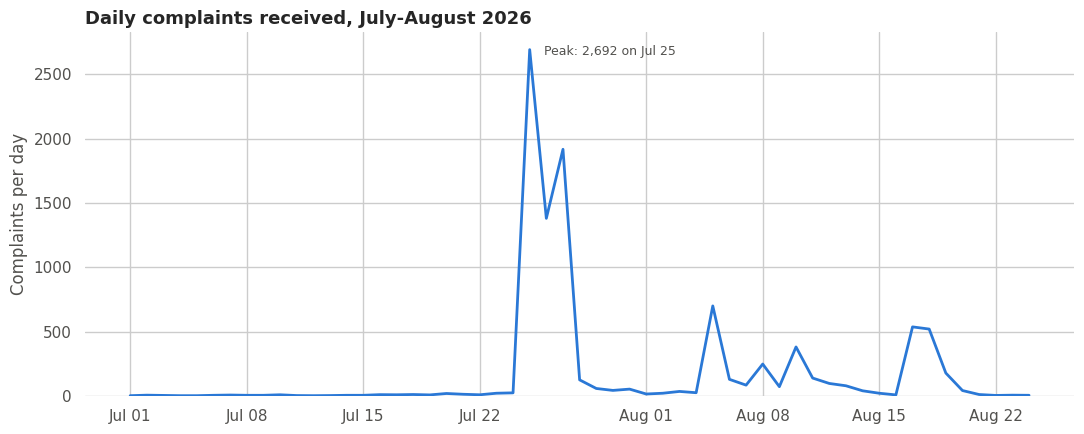

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=daily, x="date_received", y="complaint_count", color=BAR, linewidth=2, ax=ax)
peak = daily.loc[daily["complaint_count"].idxmax()]
ax.annotate(f"Peak: {peak['complaint_count']:,} on {peak['date_received']:%b %d}",
            (peak["date_received"], peak["complaint_count"]),
            xytext=(10, -4), textcoords="offset points", fontsize=9, color=INK)
ax.set_title("Daily complaints received, July-August 2026", loc="left")
ax.set(xlabel="", ylabel="Complaints per day")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** volume stays under about 30 a day until July 24, then jumps to 2,692 on July 25 and arrives in short bursts after that. Bursts this size suggest the dates reflect batch processing rather than steady consumer filing. Check this before drawing trend conclusions.

## 5. Which companies respond late most often?
*Why it matters:* the timely-response rate is the CFPB's own measure of whether a company handles complaints on time, so late responders are the institutions falling behind their peers. Companies with at least 20 complaints, to avoid ranking on one or two cases. (Same query as SQL Q5.)

In [10]:
q5 = """
select company_name, company_total, late_count,
       round(late_share * 100, 2) as pct_not_timely
from (
    select fc.company_name, cc.timely_response,
           count(*) as late_count,
           sum(count(*)) over (partition by fc.company_name) as company_total,
           ratio_to_report(count(*)) over (partition by fc.company_name) as late_share
    from consumer_complaints cc
    join financial_companies fc on fc.company_id = cc.company_id
    group by fc.company_name, cc.timely_response
) q
where timely_response = 'No'
  and company_total >= 20
order by pct_not_timely desc
"""
late = pd.read_sql(q5, engine)
late["pct_not_timely"] = late["pct_not_timely"].astype(float)
late

,company_name,company_total,late_count,pct_not_timely
0,Conduent Incorporated,56,56,100.00
1,"Shellpoint Partners, LLC",21,14,66.67
2,SYNCHRONY FINANCIAL,83,6,7.23
3,"BANK OF AMERICA, NATIONAL ASSOCIATION",66,2,3.03


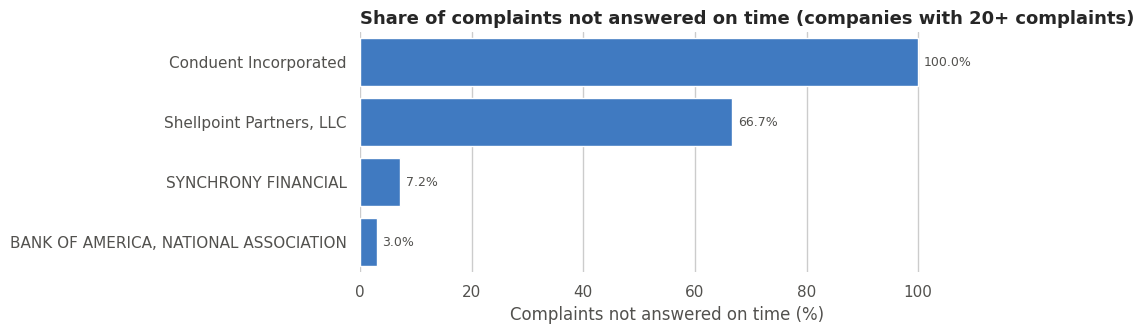

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.barplot(data=late, y="company_name", x="pct_not_timely", color=BAR, ax=ax)
label_bars(ax, fmt="{:.1f}%")
ax.set_title("Share of complaints not answered on time (companies with 20+ complaints)", loc="left")
ax.set(xlabel="Complaints not answered on time (%)", ylabel="")
ax.set_xlim(0, 110)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Finding:** only a few companies with 20+ complaints have any late responses. One of them answered none of its complaints on time, which makes it the clearest outlier in the sample. Companies with no late responses don't appear in this chart.